# Qué pagos revisar

**Minería de Datos, ITAM. Proyecto final con la metodología CRISP-DM.**

Al cierre de cada día, el equipo de riesgo de un procesador de pagos puede enviar 60 pagos ya autorizados a revisión
manual. Un fraude revisado se detiene antes del contracargo; uno no revisado se pierde completo. Este cuaderno mide
cuántos dólares de fraude entran a la cola si los 60 pagos se eligen con un modelo, frente a la mejor regla, una
logística regularizada y el enfoque de la competencia de Kaggle, **con el mismo cupo para todas las políticas**.

Datos: IEEE-CIS Fraud Detection (Vesta), copia pública OpenML 46858. El cuaderno lee lo que producen `scripts/01` a
`07`, recalcula en vivo los dólares de la prueba desde los puntajes guardados, recalcula los intervalos desde las
réplicas bootstrap y comprueba el veredicto contra el protocolo congelado (`docs/protocolo.md`).

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import SVG, Markdown, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from revisar.datos import CAT, CLAVES, CONJUNTOS, DERIVADAS, ESTADISTICAS, NUM, VESTA, _historial
from revisar.evaluacion import dinero, matriz
from revisar.figuras import autonomo, laminas
from revisar.politicas import CS, FLEXIBLES, REGLAS, puntaje
from revisar.rutas import PROCESADOS

leer = lambda n: json.loads((RAIZ / "resultados" / n).read_text(encoding="utf-8"))
S, R, X = leer("desarrollo_seleccion.json"), leer("prueba.json"), leer("exploracion.json")
L, CC, PJ = leer("lecciones.json"), leer("curvas_curso.json"), leer("presentacion.json")
VA, AX = leer("variables.json"), leer("anexo_prueba_variables.json")
FINAL, REGLA, LOGIT, PUB = S["final"], S["mejor_regla"], S["mejor_logit"], "PUBLICADO"
K, P = S["K"], ["P1", "P2"]
NOMBRE = {FINAL: "Modelo: XGBoost con F3", LOGIT: "Mejor logística (C = 0.003, F3)", REGLA: "Mejor regla: tasa por segmento × monto",
          PUB: "Solo probabilidad (enfoque de la competencia)", "R_monto": "Mayor monto primero", "oraculo": "Oráculo (conoce las etiquetas)"}
FIG = laminas()
fig = lambda clave: display(SVG(autonomo(FIG[clave])))
mil = lambda x: round(x / 1e3, 1)
pc = lambda x: f"{x * 100:+.1f}%"
ic = lambda par: f"{par[0] * 100:+.1f}% a {par[1] * 100:+.1f}%"
print(f"Modelo final: {FINAL} · mejor regla: {REGLA} · mejor logística: {LOGIT} · cupo: {K} revisiones por día")

Modelo final: XGB|F3 · mejor regla: R_segmento · mejor logística: LOGIT_C0.003|F3 · cupo: 60 revisiones por día


## 1. Comprensión del negocio

| Pregunta | Respuesta |
|---|---|
| Quién decide | El equipo de riesgo del procesador de pagos (Vesta). |
| Cuándo | Al cierre de cada día, sobre los pagos ya autorizados, con la información disponible hasta ese momento. |
| Opciones | Mandar el pago a revisión manual o dejarlo pasar. |
| Recurso | 60 revisiones por día, cerca de 2% de los pagos, iguales para todas las políticas. |
| Dinero | Dólares de los pagos etiquetados como fraude que entran a la cola. |
| Práctica actual | Vesta no la publica; la representa la mejor regla del periodo de desarrollo. |

**La matriz de confusión en dólares.** Con un cupo fijo, cada revisión que se va a un pago legítimo o a un fraude pequeño
deja fuera un fraude más grande. La métrica de la decisión es una sola celda:

| | El pago es fraude | El pago es legítimo |
|---|---|---|
| Se revisa | Fraude detenido: **la métrica que se maximiza** | Una revisión usada sin recuperar nada |
| No se revisa | Contracargo: se pierde el monto completo | Sin costo |

**Mejora significativa, fijada antes de abrir la prueba** (`docs/protocolo.md`). En cada mes de prueba:

In [2]:
U = R["umbrales"]
pd.DataFrame({"Comparador": ["Mejor regla", "Mejor logística", "Solo probabilidad"],
              "Condición": [f"ventaja ≥ {U['H1']:.0%} y límite inferior del IC 95% > 0", f"ventaja ≥ {U['H2']:.0%} y límite inferior del IC 95% > 0",
                            "límite inferior del IC 95% > 0"]}, index=["H1", "H2", "H3"])

,Comparador,Condición
H1,Mejor regla,ventaja ≥ 20% y límite inferior del IC 95% > 0
H2,Mejor logística,ventaja ≥ 10% y límite inferior del IC 95% > 0
H3,Solo probabilidad,límite inferior del IC 95% > 0


## 2. Comprensión de los datos

Días 1 a 120 (entrenamiento y desarrollo). Los días 121 a 182 no se leyeron hasta la prueba.

In [3]:
u, c = X["universo"], X["concentracion"]
pd.Series({"Pagos": f"{u['pagos']:,}", "Pagos por día (mediana)": f"{u['pagos_por_dia_mediana']:,.0f}",
           "Tasa de fraude": f"{u['tasa_fraude']:.1%}", "Fraude en dólares (miles)": f"{u['usd_fraude'] / 1e3:,.0f}",
           "Monto mediano del fraude (USD)": f"{u['monto_mediano_fraude']:.0f}", "Monto mediano legítimo (USD)": f"{u['monto_mediano_legitimo']:.0f}",
           "Cupo de 60 como parte de los pagos del día": f"{u['cupo_60_parte_pagos']:.1%}",
           "Fraude en dólares del 10% de pagos de mayor monto": f"{c['top_10pct_pagos_por_monto']:.0%}"}).to_frame("valor")

,valor
Pagos,"414,542"
Pagos por día (mediana),"3,180"
Tasa de fraude,3.5%
Fraude en dólares (miles),"2,134"
Monto mediano del fraude (USD),76
Monto mediano legítimo (USD),69
Cupo de 60 como parte de los pagos del día,1.9%
Fraude en dólares del 10% de pagos de mayor monto,53%


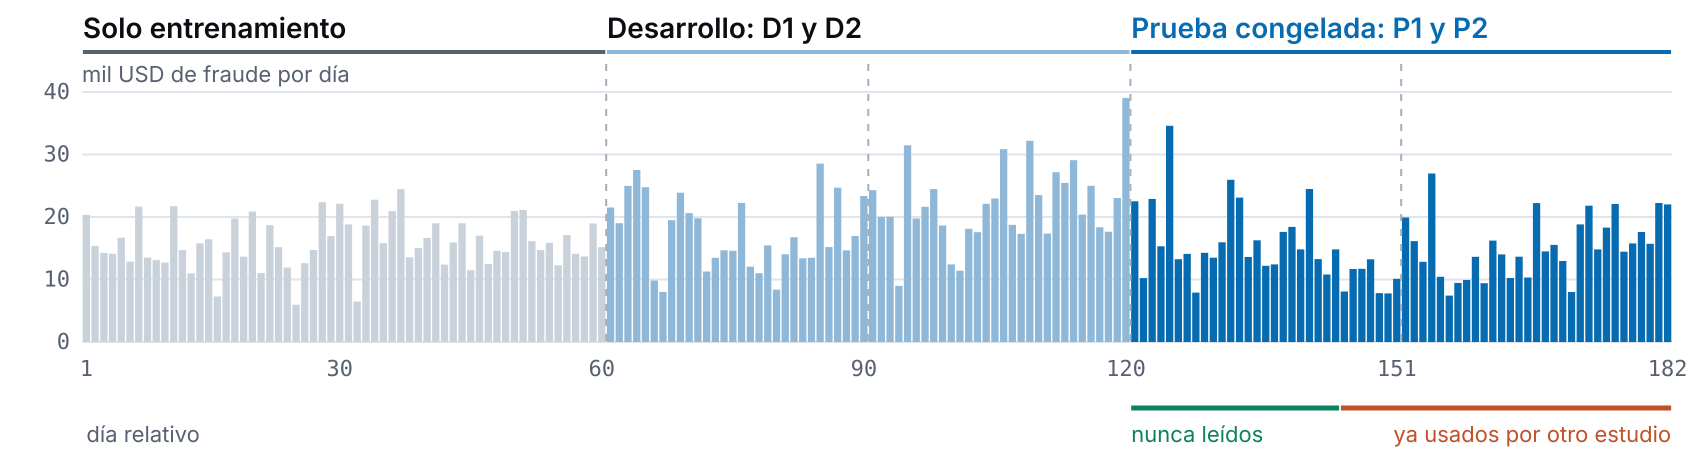

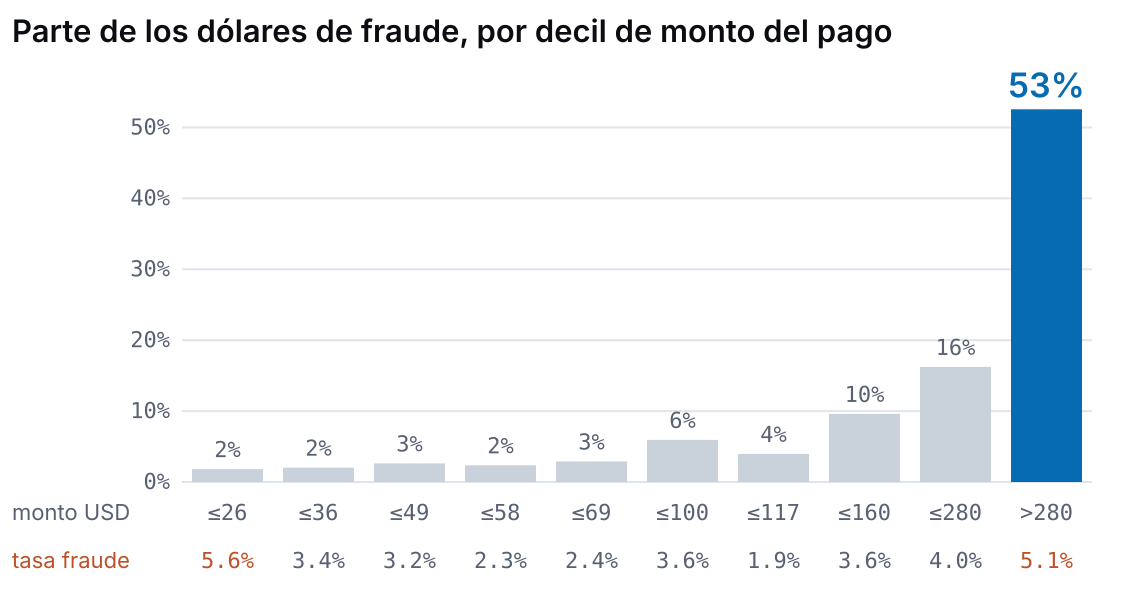

In [4]:
fig("tiempo"); fig("deciles")

**Por producto** (`ProductCD`): W concentra 72% de los pagos y 64% del fraude en dólares; C tiene la tasa más alta.

In [5]:
pd.DataFrame({k: {"pagos": f"{v['pagos']:,}", "tasa de fraude": f"{v['tasa']:.1%}", "fraude (mil USD)": f"{v['usd_fraude'] / 1e3:,.0f}",
                  "parte de los pagos": f"{v['parte_pagos']:.0%}", "parte del fraude en USD": f"{v['parte_usd_fraude']:.0%}"}
              for k, v in X["producto"].items()}).T

,pagos,tasa de fraude,fraude (mil USD),parte de los pagos,parte del fraude en USD
C,"50,136",11.2%,267,12%,13%
H,"28,134",4.5%,206,7%,10%
R,"30,185",3.5%,256,7%,12%
S,"7,214",6.0%,33,2%,2%
W,"298,873",2.1%,"1,373",72%,64%


**Calidad de los datos.** Los faltantes son frecuentes en dispositivo e identidad y se conservan con un indicador, porque
el faltante también es informativo. La etiqueta sigue la regla de Vesta: un contracargo se propaga a los pagos
posteriores de la misma cuenta, dirección o correo.

In [6]:
ck = X["cliente"]
display(pd.Series({k: f"{v:.1%}" for k, v in X["faltantes"].items()}).rename("parte faltante").to_frame())
pd.Series({"Fraudes en clientes con dos o más pagos": f"{ck['fraudes_en_clientes_con_2_o_mas']:.0%}",
           "Clientes con fraude en los que todo es fraude": f"{ck['clientes_con_fraude_todo_fraude']:.0%}"}).to_frame("valor")

,parte faltante
D1,0.1%
dist1,61.8%
id_01,73.4%
addr1,11.5%
P_emaildomain,15.6%
DeviceType,74.0%


,valor
Fraudes en clientes con dos o más pagos,77%
Clientes con fraude en los que todo es fraude,62%


## 3. Preparación de los datos

Los pagos se ordenan por segundo. Para cinco llaves (cuatro de tarjeta y una de cliente) se calculan cinco medidas con
**solo pagos de segundos estrictamente anteriores** y nunca la etiqueta. El cliente se reconstruye como tarjeta +
dirección + fecha de alta (día del pago − `D1`).

In [7]:
for k, v in CLAVES.items():
    print(f"llave {k:<20} {' + '.join(v)}")
print("Medidas por llave:", ", ".join(ESTADISTICAS))
for n, (num, cat) in CONJUNTOS.items():
    print(f"{n}: {len(num)} numéricas y {len(cat)} categóricas")
assert not set(VESTA) & set(CONJUNTOS["F3"][0]), "F3 no debe usar las columnas opacas de Vesta"
assert "isFraud" not in CONJUNTOS["F3"][0] + CONJUNTOS["F3"][1]
print("F3 no usa columnas opacas ni la etiqueta.")

llave tarjeta              card1
llave tarjeta_dir          card1 + addr1
llave tarjeta_dir_correo   card1 + addr1 + P_emaildomain
llave tarjeta_completa     card1 + card2 + card3 + card4 + card5 + card6
llave cliente              card1 + addr1 + alta
Medidas por llave: previos, ultimo_dia, ultima_semana, segundos_desde, razon_monto
F1: 30 numéricas y 37 categóricas
F2: 50 numéricas y 37 categóricas
F3: 56 numéricas y 37 categóricas
F4: 423 numéricas y 37 categóricas
F3 no usa columnas opacas ni la etiqueta.


**El historial, en vivo.** Cuatro pagos de un mismo cliente; los dos últimos ocurren en el mismo segundo. La función
del proyecto (`_historial`) no deja que se vean entre sí.

In [8]:
t = np.array([0, 3_600, 90_000, 90_000])
monto = np.array([30.0, 40.0, 120.0, 10.0])
h = _historial(t, monto, np.zeros(4, int))
pd.DataFrame({"segundo": t, "monto": monto, **h}).rename(columns={"previos": "pagos previos", "ultimo_dia": "último día",
    "ultima_semana": "última semana", "segundos_desde": "segundos desde el anterior", "razon_monto": "monto / promedio previo"})

,segundo,monto,pagos previos,último día,última semana,segundos desde el anterior,monto / promedio previo
0,0,30.0,0.0,0.0,0.0,NaN,NaN
1,3600,40.0,1.0,1.0,1.0,3600.0,1.333
2,90000,120.0,2.0,1.0,2.0,86400.0,3.429
3,90000,10.0,2.0,1.0,2.0,86400.0,0.286


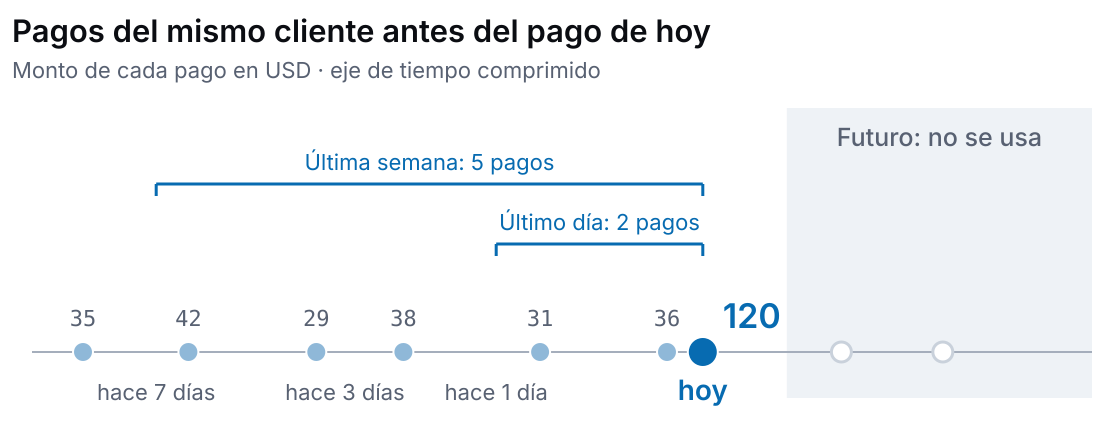

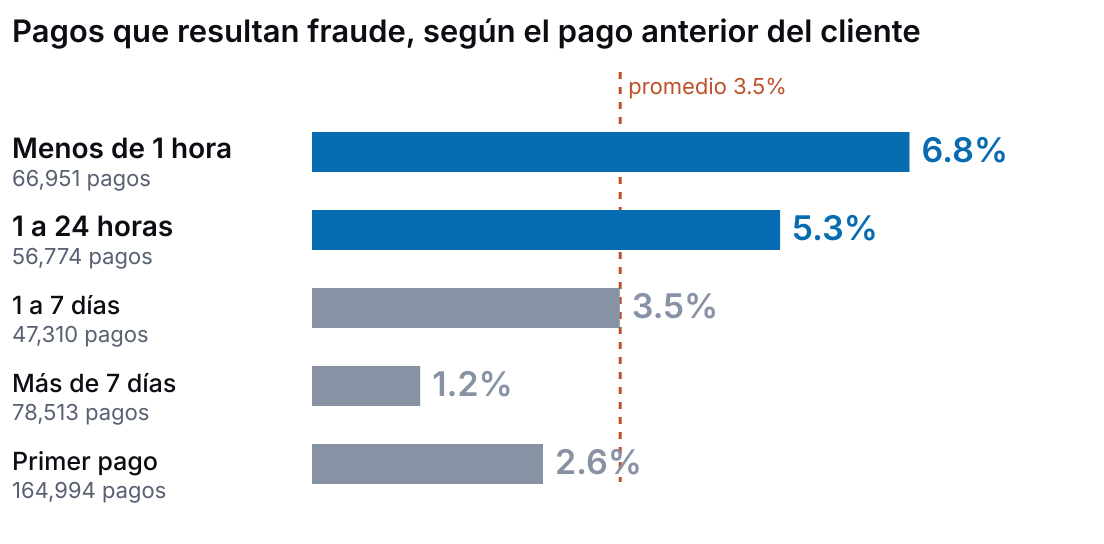

In [9]:
fig("tuberia"); fig("cliente")

## 4. Modelado

Dos bloques de desarrollo: D1 (días 61–90, entrena con 1–30) y D2 (días 91–120, entrena con 1–60). El margen de 30
días representa el tiempo en que madura la etiqueta. La regla de selección (`docs/criterio_desarrollo.md`) se escribió
antes de correr el torneo. Se recalcula aquí desde los dólares de cada política.

In [10]:
dv = pd.DataFrame(S["dolares"]).T
dv["total"] = dv["D1"] + dv["D2"]
display((dv / 1e3).round(1).sort_values("total", ascending=False).rename(columns=lambda c: f"{c} (mil USD)"))

elegibles = [f"{f}|{c}" for f in FLEXIBLES for c in ("F2", "F3")]
mejor = dv.loc[elegibles, "total"].idxmax()
if mejor.startswith("ENS"):
    unico = dv.loc[[e for e in elegibles if not e.startswith("ENS")], "total"].idxmax()
    if dv.loc[mejor, "total"] < 1.01 * dv.loc[unico, "total"]:
        mejor = unico
logit = dv.loc[[f"LOGIT_C{c}|{f}" for c in CS for f in ("F2", "F3")], "total"].idxmax()
regla = dv.loc[list(REGLAS), "total"].idxmax()
supera = all(dv.loc[mejor, b] > dv.loc[logit, b] for b in ("D1", "D2"))
final = mejor if supera else logit
assert (final, logit, regla, supera) == (S["final"], S["mejor_logit"], S["mejor_regla"], S["supera_lineal_en_ambos"])
print(f"Regla recalculada: modelo final {final}, mejor logística {logit}, mejor regla {regla}; "
      f"el modelo supera a la logística en ambos bloques: {supera}")

,D1 (mil USD),D2 (mil USD),total (mil USD)
XGB|F4,219.7,299.0,518.8
XGB|F3,183.7,264.2,447.9
ENS|F3,164.6,273.0,437.6
ENS|F2,159.2,271.9,431.1
XGB|F2,171.0,256.4,427.4
XGB|F1,172.2,254.7,426.9
XGB_pond|F3,168.6,244.3,413.0
RF|F3,142.9,255.0,397.9
LOGIT_C0.003|F3,142.8,254.2,397.0
RF|F2,138.4,254.5,392.8


Regla recalculada: modelo final XGB|F3, mejor logística LOGIT_C0.003|F3, mejor regla R_segmento; el modelo supera a la logística en ambos bloques: True


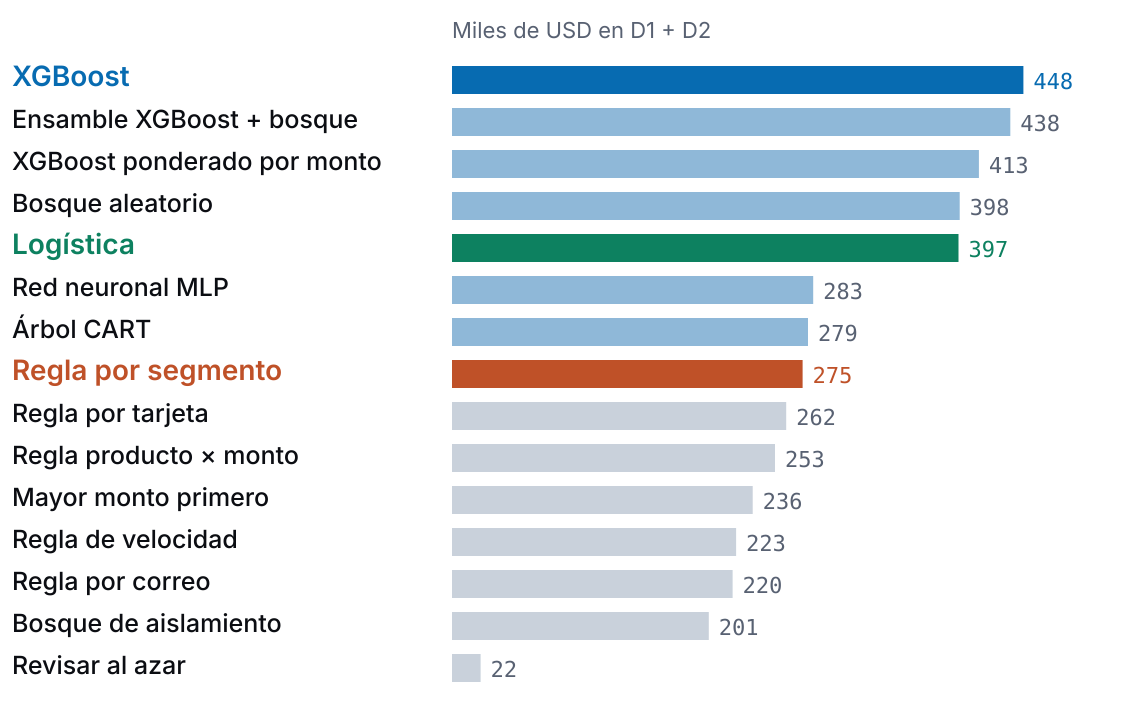

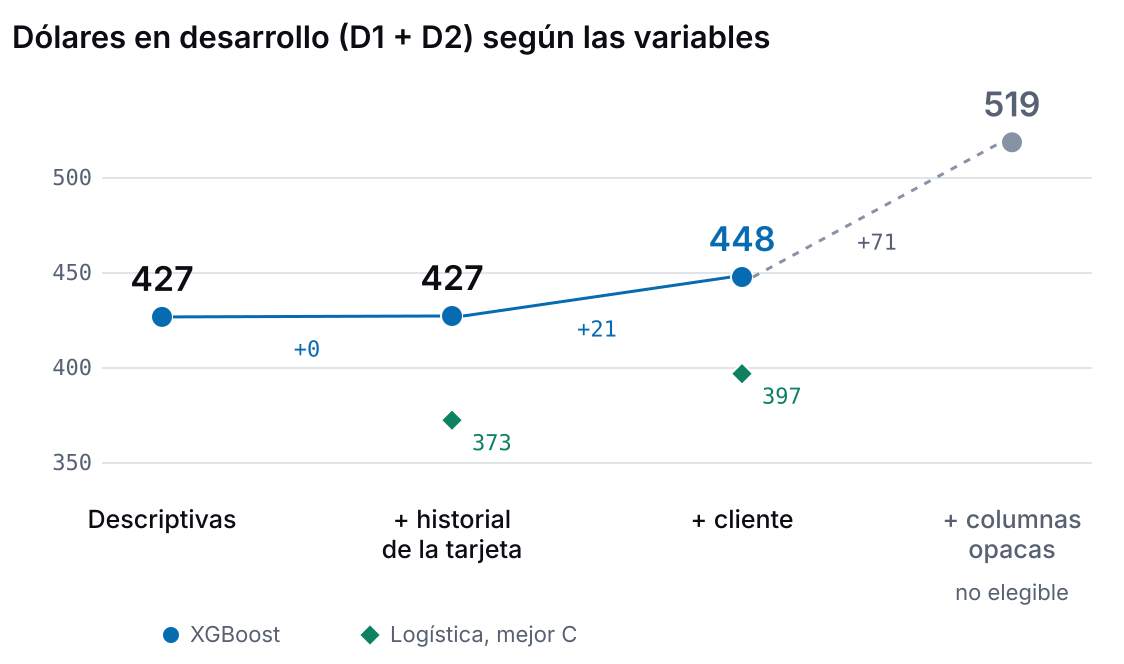

In [11]:
fig("torneo"); fig("ablacion")

**Ablación de variables con el mismo XGBoost.** F4 agrega las columnas opacas de Vesta. Darían más dinero, pero la
descripción pública no dice en qué momento se calculan; por eso quedaron fuera antes de la prueba.

In [12]:
pd.DataFrame({c: dv.loc[f"XGB|{c}", ["D1", "D2", "total"]] / 1e3 for c in ("F1", "F2", "F3", "F4")}).T.round(1)

,D1,D2,total
F1,172.2,254.7,426.9
F2,171.0,256.4,427.4
F3,183.7,264.2,447.9
F4,219.7,299.0,518.8


**Regularización de la logística: se elige por dólares, no por AUC.**

In [13]:
rg = pd.DataFrame(L["regularizacion"])
rg.assign(usd=(rg["usd"] / 1e3).round(1)).pivot(index="C", columns="conjunto", values=["usd", "auc"]).round(3)

usd           auc       
conjunto     F2     F3     F2     F3
C                                   
0.001     369.6  382.8  0.799  0.803
0.003     372.5  397.0  0.803  0.807
0.010     366.1  388.7  0.806  0.809
0.030     362.1  377.0  0.805  0.807
0.100     345.0  357.4  0.800  0.801

**Diagnósticos en D2:** importancia por permutación en dólares y prueba de cordura con las etiquetas permutadas.

In [14]:
dg = S["diagnosticos_D2"]
display((pd.Series(dg["importancia_usd"]) / 1e3).round(1).sort_values(ascending=False).rename("mil USD que se pierden al permutar").to_frame())
pd.Series({"Modelo": dg["cordura"]["base"], "Etiquetas permutadas": dg["cordura"]["etiquetas_barajadas"],
           "Revisar al azar (esperado)": dg["cordura"]["azar_esperado"], "Árbol de profundidad 3": dg["arbol"]["usd_D2"]}).div(1e3).round(1).rename("mil USD en D2").to_frame()

,mil USD que se pierden al permutar
monto y centavos,74.7
coincidencias M1-M9,36.9
dispositivo e identidad,36.8
historial del cliente,34.8
tarjeta,18.3
correo,15.1
producto,2.3
historial de la tarjeta,-1.7
dirección y distancia,-2.3
hora y día,-2.3


,mil USD en D2
Modelo,264.2
Etiquetas permutadas,117.3
Revisar al azar (esperado),12.3
Árbol de profundidad 3,159.9


## 5. Evaluación en los dos meses de prueba

P1: días 121–151 (entrena con 1–90). P2: días 152–182 (entrena con 1–121). Todo quedó congelado antes de leerlos
y la prueba se corrió una vez. **Recálculo en vivo:** se toman los puntajes guardados de cada pago y se arma la
cola de 60 de cada día con el código congelado de `src/revisar/evaluacion.py`.

In [15]:
vivo = {}
for x in P:
    d = pd.read_parquet(PROCESADOS / f"prueba_puntajes_{x}.parquet")
    dia, y, m = d["dia"].to_numpy(), d["fraude"].to_numpy(), d["monto"].to_numpy()
    s = {n: puntaje(n.split("|")[0], d[n].to_numpy(), m) for n in (FINAL, LOGIT, REGLA, "R_monto")}  # probabilidad × monto
    s[PUB] = puntaje(FINAL.split("|")[0], d[FINAL].to_numpy(), m, "p")   # el mismo modelo, ordenado solo por probabilidad
    s["oraculo"] = y * m
    vivo[x] = {n: dinero(v, dia, y, m, K) for n, v in s.items()}
    if x == "P2":
        mz = {n: matriz(s[n], dia, y, m, K) for n in (FINAL, REGLA)}
tab = pd.DataFrame({x: {NOMBRE[n]: v / 1e3 for n, v in vivo[x].items()} for x in P}).round(1)
tab.columns = [f"{x}: mil USD" for x in P]
for x in P:
    tab[f"{x}: parte del oráculo"] = [f"{vivo[x][n] / vivo[x]['oraculo']:.0%}" for n in vivo[x]]
dif = max(abs(vivo[x][n] - R[x]["usd"][n]) for x in P for n in vivo[x])
assert dif < 0.01, "el recálculo no reproduce resultados/prueba.json"
print(f"Diferencia máxima contra resultados/prueba.json: {dif:.6f} USD")
tab

Diferencia máxima contra resultados/prueba.json: 0.000000 USD


,P1: mil USD,P2: mil USD,P1: parte del oráculo,P2: parte del oráculo
Modelo: XGBoost con F3,211.4,226.7,49%,52%
"Mejor logística (C = 0.003, F3)",186.9,185.5,43%,42%
Mejor regla: tasa por segmento × monto,162.6,138.7,38%,32%
Mayor monto primero,131.2,120.9,30%,28%
Solo probabilidad (enfoque de la competencia),100.6,129.9,23%,30%
Oráculo (conoce las etiquetas),432.5,438.6,100%,100%


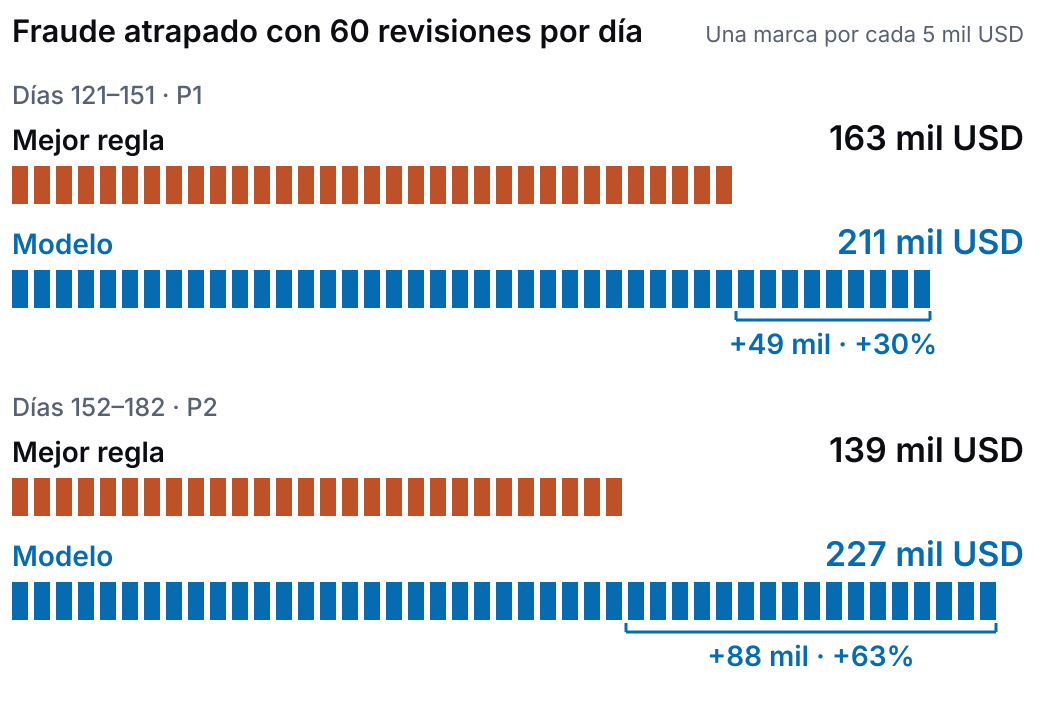

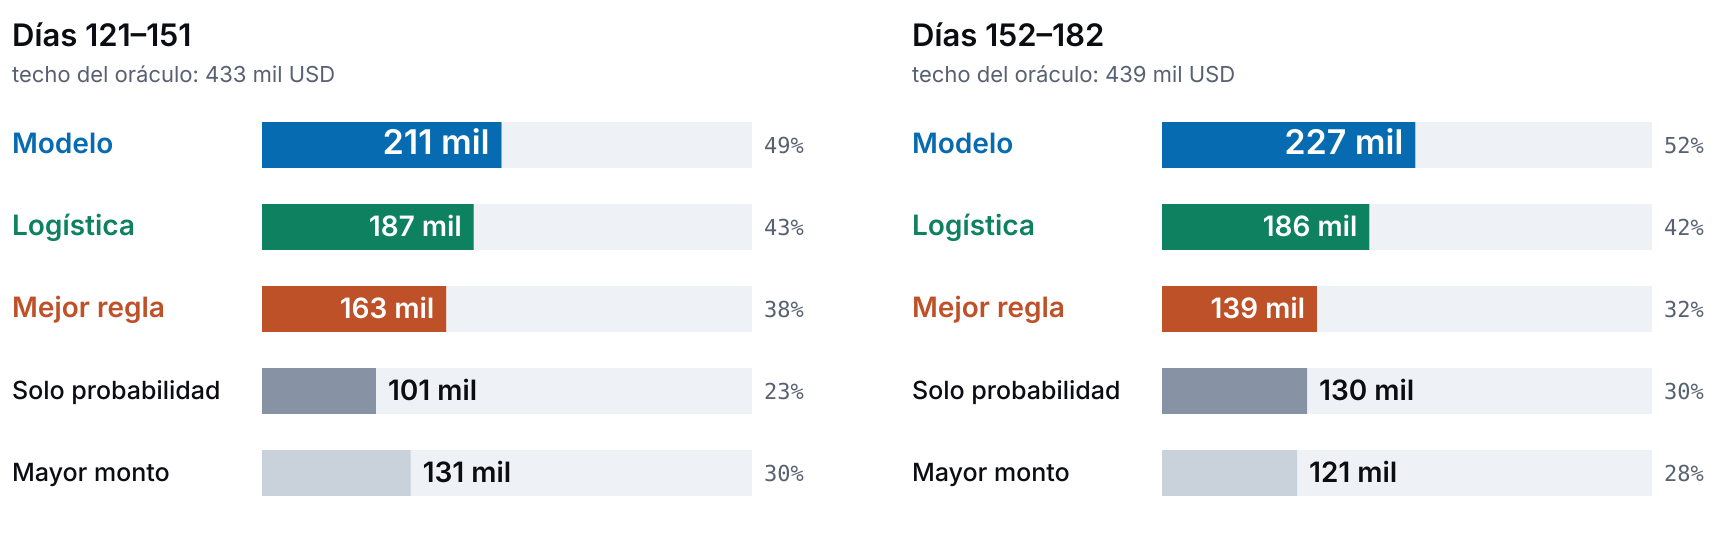

In [16]:
fig("resultado"); fig("prueba")

**Intervalos pareados.** Cada réplica remuestrea días con reemplazo, los mismos para todas las políticas. Se recalculan
desde las 1,000 réplicas guardadas y se comprueba el veredicto.

In [17]:
filas, veredicto = [], {}
for x in P:
    b = pd.read_csv(RAIZ / "resultados" / f"bootstrap_{x}.csv")
    cx = {}
    for c in (REGLA, LOGIT, PUB):
        rel = b[FINAL] / b[c] - 1
        lo, hi = rel.quantile(0.025), rel.quantile(0.975)
        assert abs(lo - R[x]["contrastes"][c]["rel_ic95"][0]) < 1e-9 and abs(hi - R[x]["contrastes"][c]["rel_ic95"][1]) < 1e-9
        cx[c] = (vivo[x][FINAL] / vivo[x][c] - 1, lo)
        filas.append({"periodo": x, "contra": NOMBRE[c], "ventaja": pc(cx[c][0]), "IC 95%": ic((lo, hi))})
    veredicto[x] = {"H1_regla": cx[REGLA][0] >= U["H1"] and cx[REGLA][1] > 0,
                    "H2_logistica": cx[LOGIT][0] >= U["H2"] and cx[LOGIT][1] > 0, "H3_publicado": cx[PUB][1] > 0}
assert veredicto == R["veredicto"]
display(pd.DataFrame(filas).set_index(["periodo", "contra"]))
display(pd.DataFrame(veredicto).rename(index={"H1_regla": "H1 · mejor regla", "H2_logistica": "H2 · mejor logística", "H3_publicado": "H3 · solo probabilidad"}))
print("Éxito del caso (H1, H2 y H3 en los dos meses):", all(all(v.values()) for v in veredicto.values()))

ventaja            IC 95%
periodo contra                                                                  
P1      Mejor regla: tasa por segmento × monto          +30.1%   +16.8% a +49.8%
        Mejor logística (C = 0.003, F3)                 +13.1%    +7.0% a +21.8%
        Solo probabilidad (enfoque de la competencia)  +110.1%  +76.9% a +147.4%
P2      Mejor regla: tasa por segmento × monto          +63.4%   +39.7% a +97.0%
        Mejor logística (C = 0.003, F3)                 +22.2%    +8.7% a +39.3%
        Solo probabilidad (enfoque de la competencia)   +74.5%   +54.7% a +98.3%

,P1,P2
H1 · mejor regla,True,True
H2 · mejor logística,True,True
H3 · solo probabilidad,True,True


Éxito del caso (H1, H2 y H3 en los dos meses): True


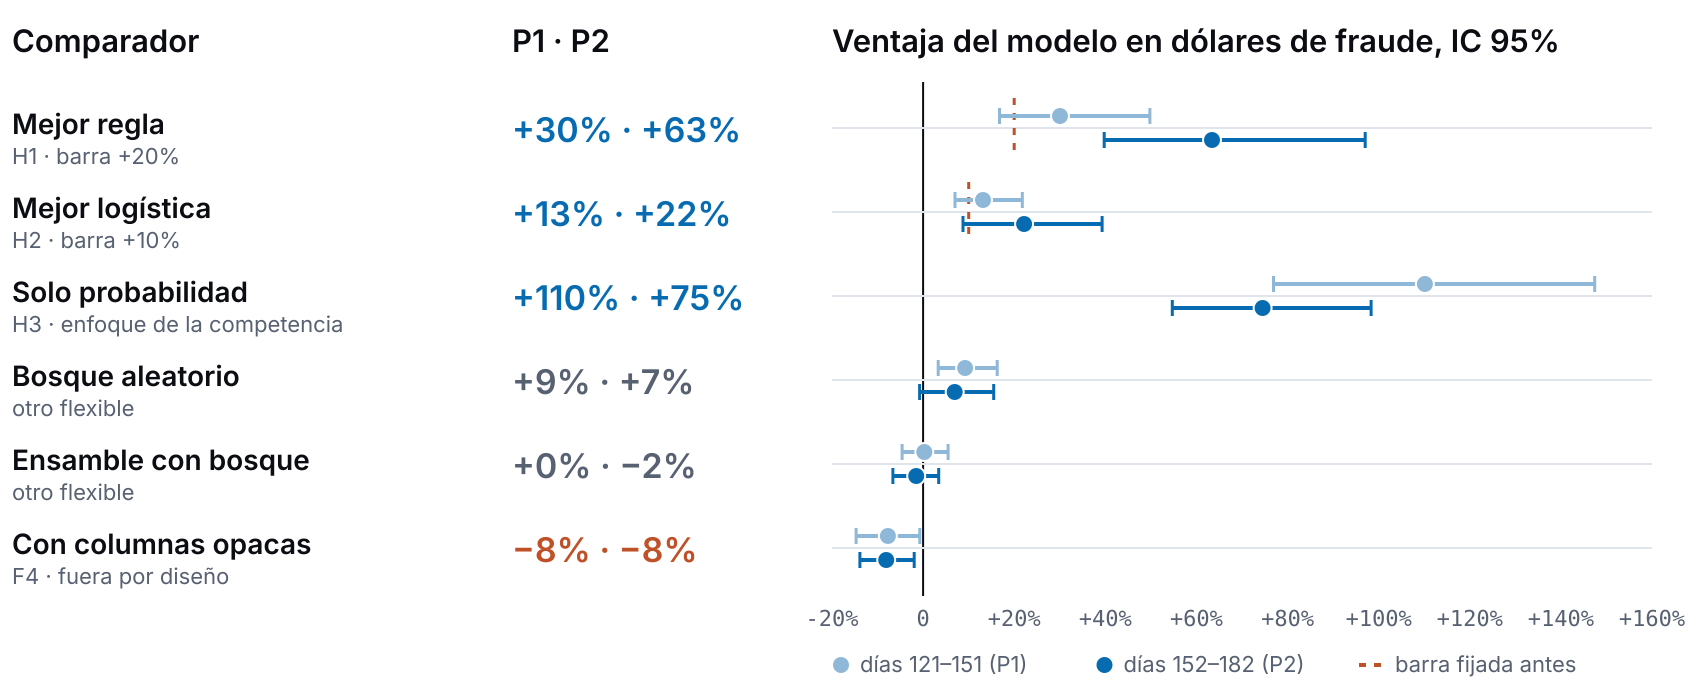

In [18]:
fig("intervalos")

**Matriz de confusión en dólares, P2.** Con el mismo cupo, el modelo cambia qué pagos entran a la cola.

In [19]:
pd.DataFrame({NOMBRE[n]: {"fraude revisado (mil USD)": mil(v["revisado_fraude"]["usd"]), "fraudes revisados": v["revisado_fraude"]["pagos"],
                           "revisiones a legítimos": v["revisado_legitimo"]["pagos"], "fraude que pasa (mil USD)": mil(v["no_revisado_fraude"]["usd"]),
                           "precisión de la cola": f"{v['precision']:.0%}", "parte del fraude del mes": f"{v['parte_usd_fraude']:.0%}"}
              for n, v in mz.items()})

,Modelo: XGBoost con F3,Mejor regla: tasa por segmento × monto
fraude revisado (mil USD),226.7,138.7
fraudes revisados,511,190
revisiones a legítimos,1349,1670
fraude que pasa (mil USD),250.7,338.6
precisión de la cola,27%,10%
parte del fraude del mes,47%,29%


**Las métricas del capítulo 4 del curso.** No revisar nada tiene la mayor exactitud. Las métricas de conteo prefieren
ordenar solo por probabilidad; en dólares gana el modelo.

In [20]:
op = pd.DataFrame(CC["operacion"]).T[["exactitud", "precision", "recall", "f1", "usd"]].astype(float)
op["usd"] = (op["usd"] / 1e3).round(0)
op.rename(index={"modelo": "Modelo (probabilidad × monto)", "solo_p": "Solo probabilidad", "logistica": "Mejor logística",
                 "regla": "Mejor regla", "monto": "Mayor monto primero", "nunca": "No revisar nada"},
          columns={"precision": "precisión", "usd": "mil USD en la cola"}).round(3)

,exactitud,precisión,recall,f1,mil USD en la cola
Modelo (probabilidad × monto),0.957,0.300,0.184,0.228,438.0
Solo probabilidad,0.964,0.453,0.278,0.345,231.0
Mejor logística,0.953,0.191,0.117,0.146,372.0
Mejor regla,0.949,0.110,0.067,0.083,301.0
Mayor monto primero,0.947,0.060,0.037,0.046,252.0
No revisar nada,0.966,NaN,0.000,0.000,0.0


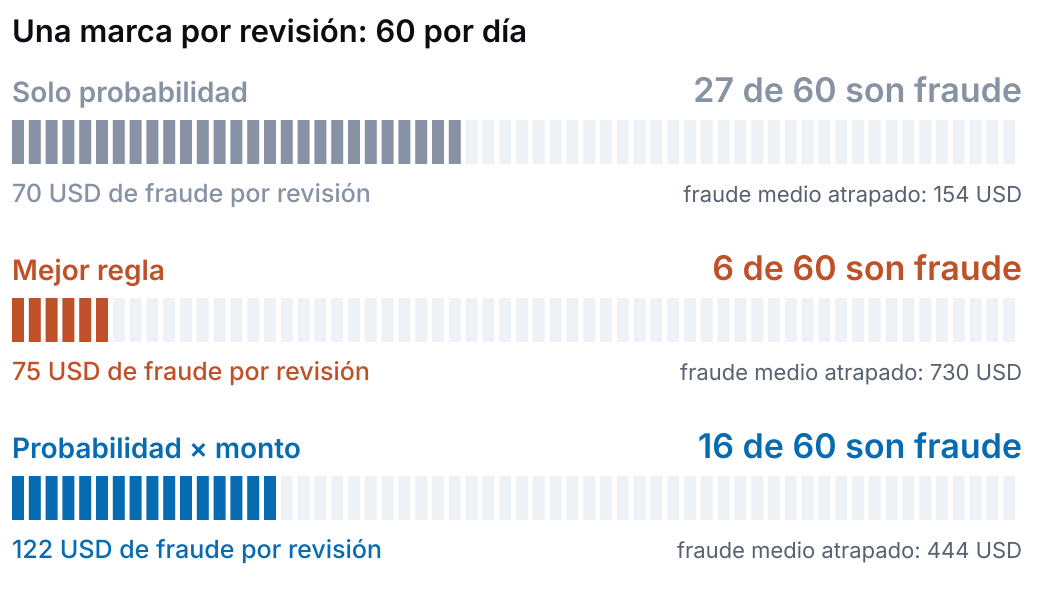

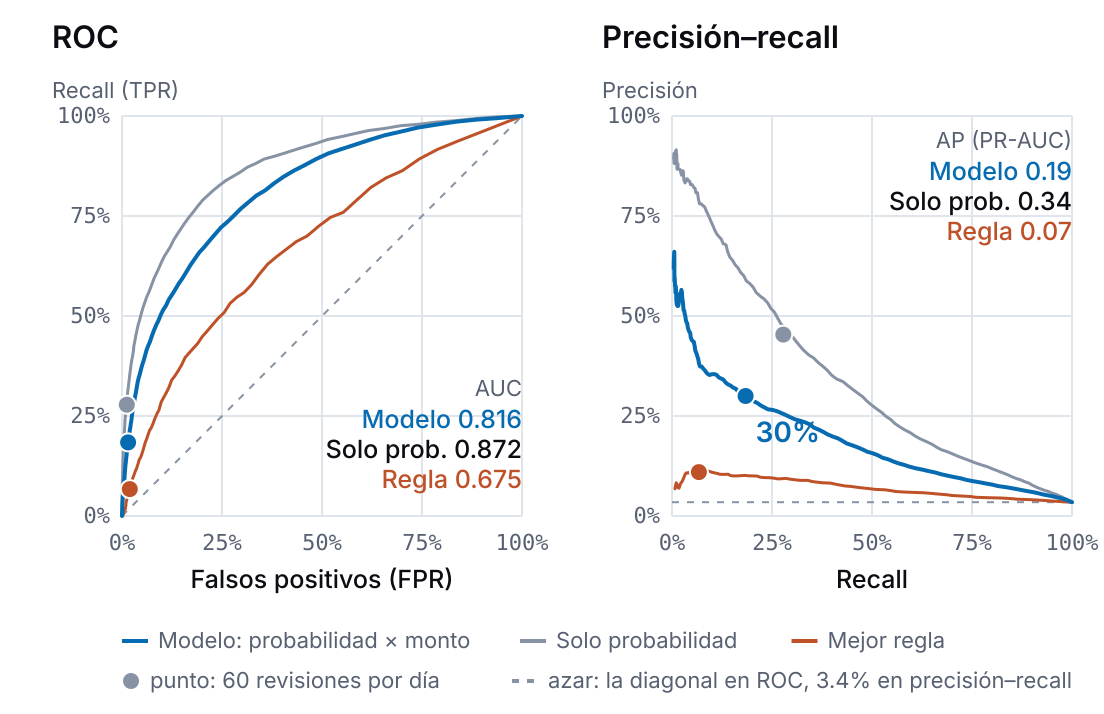

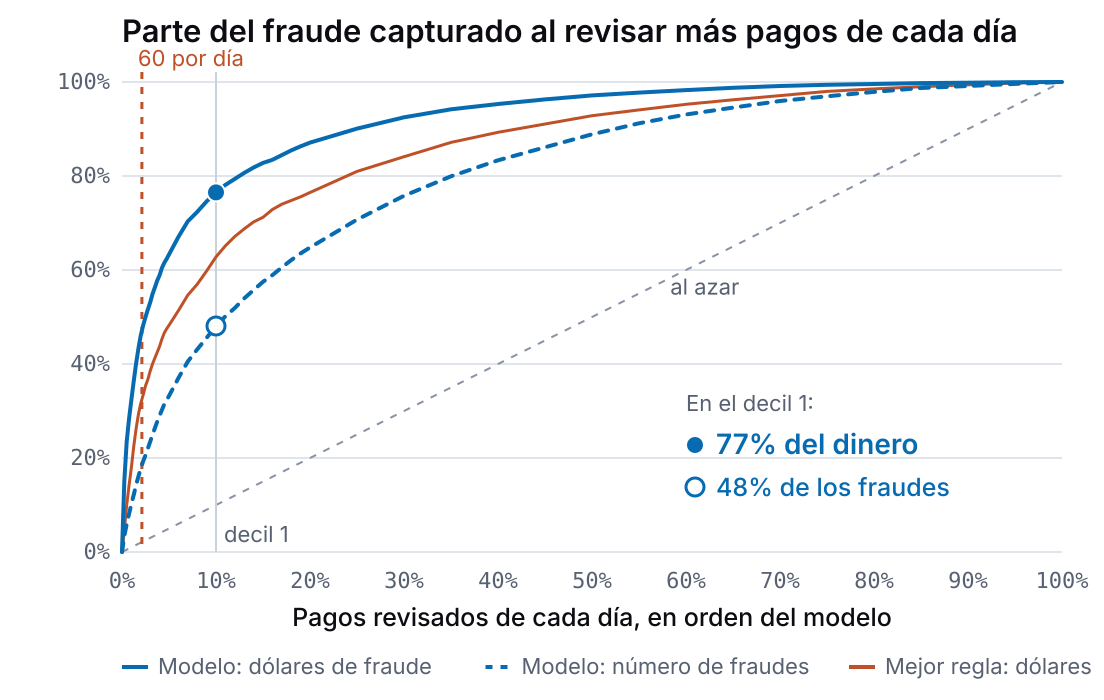

In [21]:
fig("exactitud"); fig("roc"); fig("ganancia")

**Costo por revisión.** Cada política elige su cupo en desarrollo para cada costo; el neto (recuperado − costo) se
mide en la prueba.

In [22]:
ct = pd.DataFrame([{"costo por revisión": e["costo"], "recupera": f"{e['recupera']:.0%}",
                    **{f"{k}: cupo": e[k]["K"] for k in ("modelo", "logistica", "regla")},
                    **{f"{k}: neto (mil USD)": mil(e[k]["neto_prueba"]) for k in ("modelo", "logistica", "regla")}} for e in L["costos"]])
gana = sum(e["modelo"]["neto_prueba"] > max(e["logistica"]["neto_prueba"], e["regla"]["neto_prueba"]) for e in L["costos"])
print(f"El modelo deja más neto que la regla y que la logística en {gana} de {len(L['costos'])} escenarios")
ct

El modelo deja más neto que la regla y que la logística en 14 de 14 escenarios


,costo por revisión,recupera,modelo: cupo,logistica: cupo,regla: cupo,modelo: neto (mil USD),logistica: neto (mil USD),regla: neto (mil USD)
0,1,100%,1498,1500,1494,832.1,815.5,795.9
1,2,100%,1117,1353,1491,766.0,729.4,702.6
2,5,100%,621,709,764,648.0,588.8,544.1
3,10,100%,450,424,489,513.4,465.0,399.3
4,20,100%,178,188,205,423.1,358.2,268.9
5,50,100%,66,70,48,249.4,180.1,114.2
6,100,100%,30,17,0,128.0,54.0,0.0
7,1,50%,1117,1353,1491,383.0,364.7,351.3
8,2,50%,815,878,996,334.8,312.3,289.4
9,5,50%,450,424,489,256.7,232.5,199.6


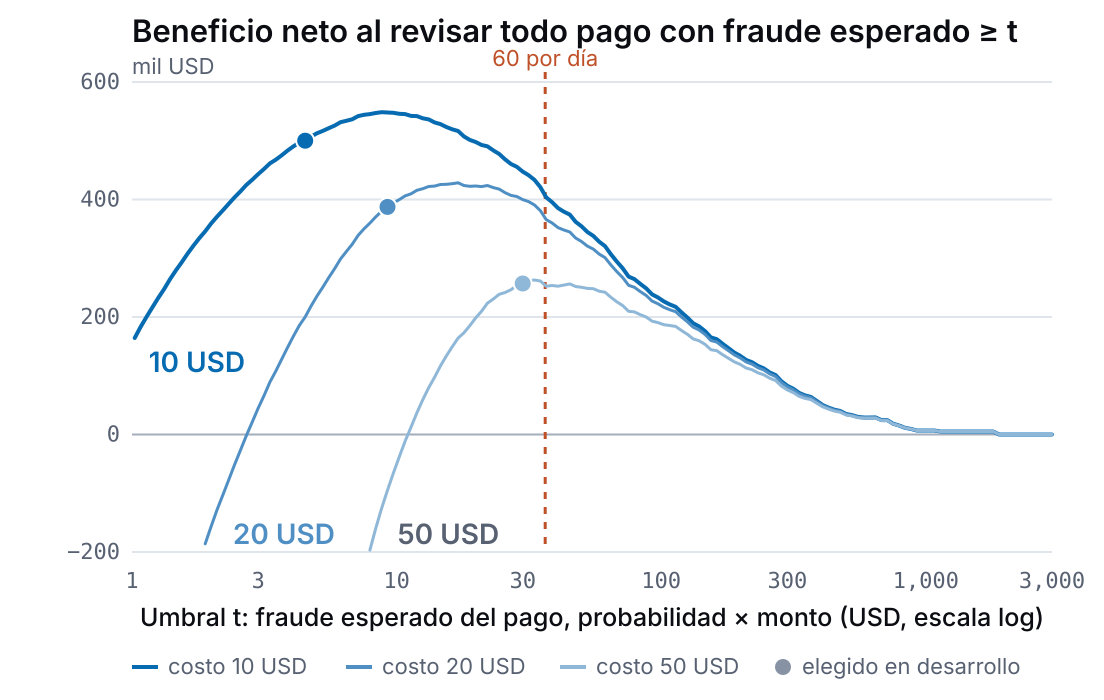

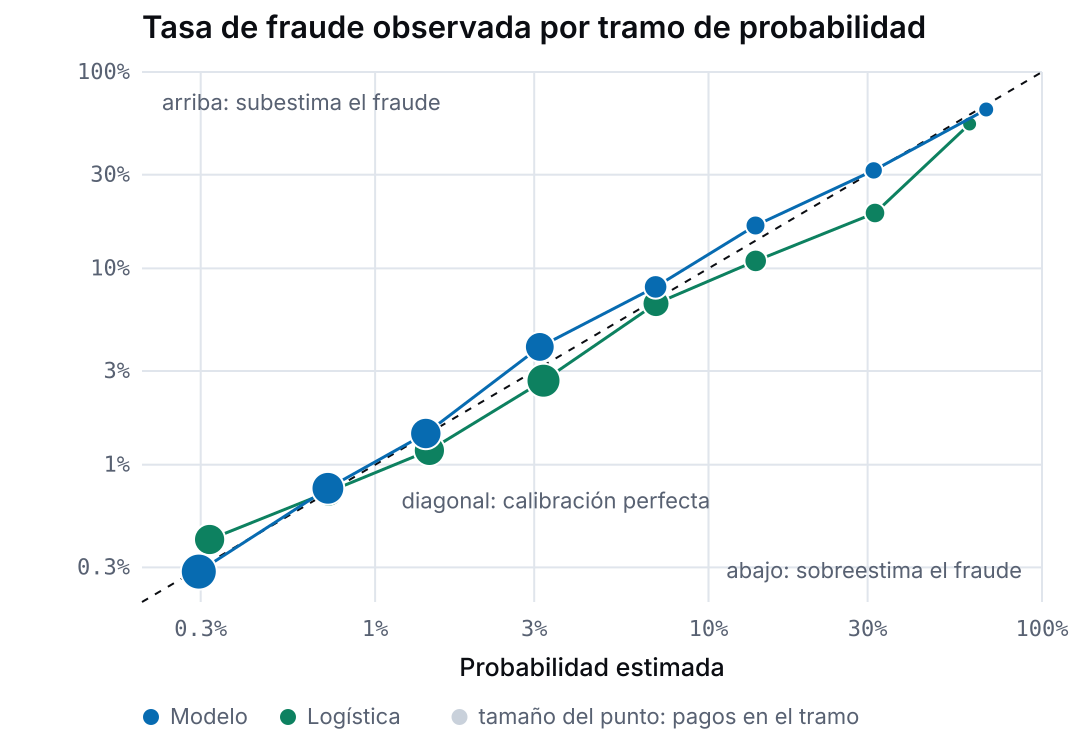

In [23]:
fig("montana"); fig("calibracion")

In [24]:
pd.Series({"Modelo": L["calibracion"]["modelo"]["brier"], "Logística": L["calibracion"]["logistica"]["brier"],
           "Asignar a todos la tasa media": L["brier_base"]}).round(4).rename("error de Brier, días 121–182").to_frame()

,"error de Brier, días 121–182"
Modelo,0.027
Logística,0.031
Asignar a todos la tasa media,0.033


**Robustez.** Ventaja del modelo con otros cupos, sin los pagos más caros, con el monto topado y en los días 121–144,
que ningún estudio anterior había leído.

In [25]:
rb = {}
for x in P:
    r = R[x]["robustez"]
    for c, nom in ((REGLA, "regla"), (LOGIT, "logística")):
        rb[f"{nom} · {x}"] = {"principal (60 por día)": pc(R[x]["contrastes"][c]["rel"]), "30 por día": pc(r["K"][c]["30"]),
                              "120 por día": pc(r["K"][c]["120"]), "sin pagos sobre el p99": pc(r["sin_top1"][c]),
                              "monto topado en el p99": pc(r["topado"][c]), "días que gana": f"{R[x]['dias_que_gana'][c]} de {R[x]['n_dias']}",
                              "días 121–144": pc(R[x]["limpio"]["contrastes"][c]["rel"]) if x == "P1" else "—"}
pd.DataFrame(rb)

,regla · P1,logística · P1,regla · P2,logística · P2
principal (60 por día),+30.1%,+13.1%,+63.4%,+22.2%
30 por día,+80.6%,+13.6%,+89.8%,+28.6%
120 por día,+25.7%,+12.0%,+44.1%,+15.5%
sin pagos sobre el p99,+20.6%,+8.8%,+58.0%,+22.1%
monto topado en el p99,+37.1%,+15.6%,+77.9%,+28.7%
días que gana,26 de 31,24 de 31,28 de 31,24 de 31
días 121–144,+22.6%,+11.0%,—,—


**Traza del dinero.** Cada dólar de fraude del mes cae en una sola categoría y las cuatro suman el fraude total.

In [26]:
tr = pd.DataFrame(PJ["traza"]).T
for x in P:
    assert abs(tr.loc[x, ["ambos", "solo_modelo", "solo_regla", "ninguno"]].sum() - tr.loc[x, "fraude_total"]) < 0.01
(tr[["fraude_total", "ambos", "solo_modelo", "solo_regla", "ninguno"]] / 1e3).round(1).rename(columns=lambda c: f"{c} (mil USD)")

,fraude_total (mil USD),ambos (mil USD),solo_modelo (mil USD),solo_regla (mil USD),ninguno (mil USD)
P1,472.7,134.6,76.9,28.0,233.2
P2,477.4,111.6,115.1,27.2,223.5


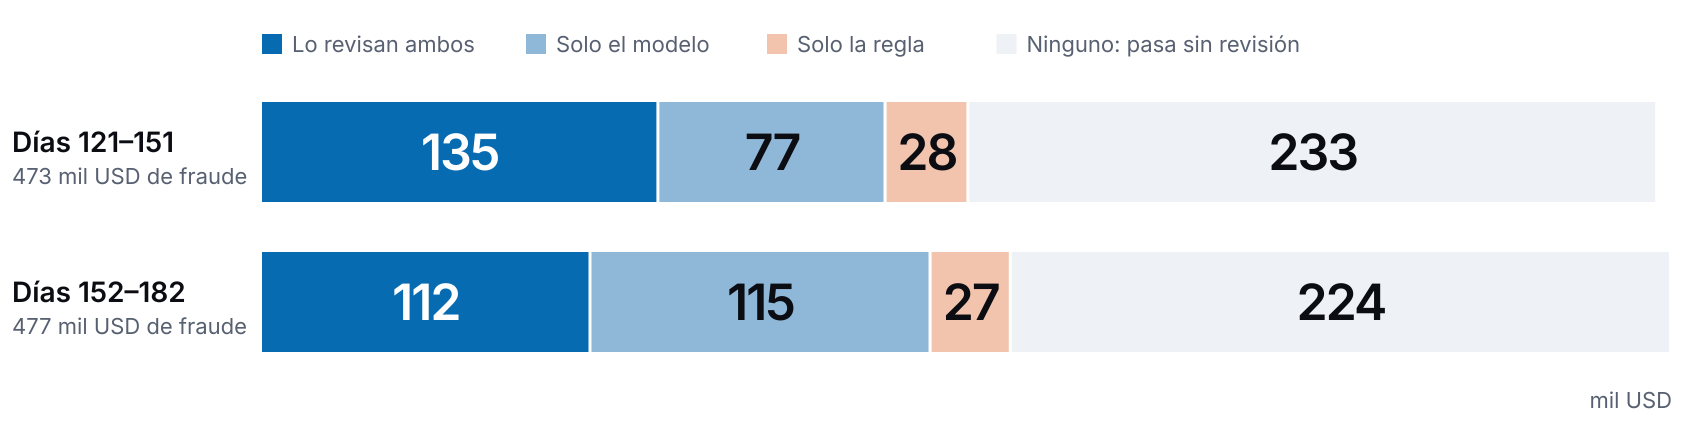

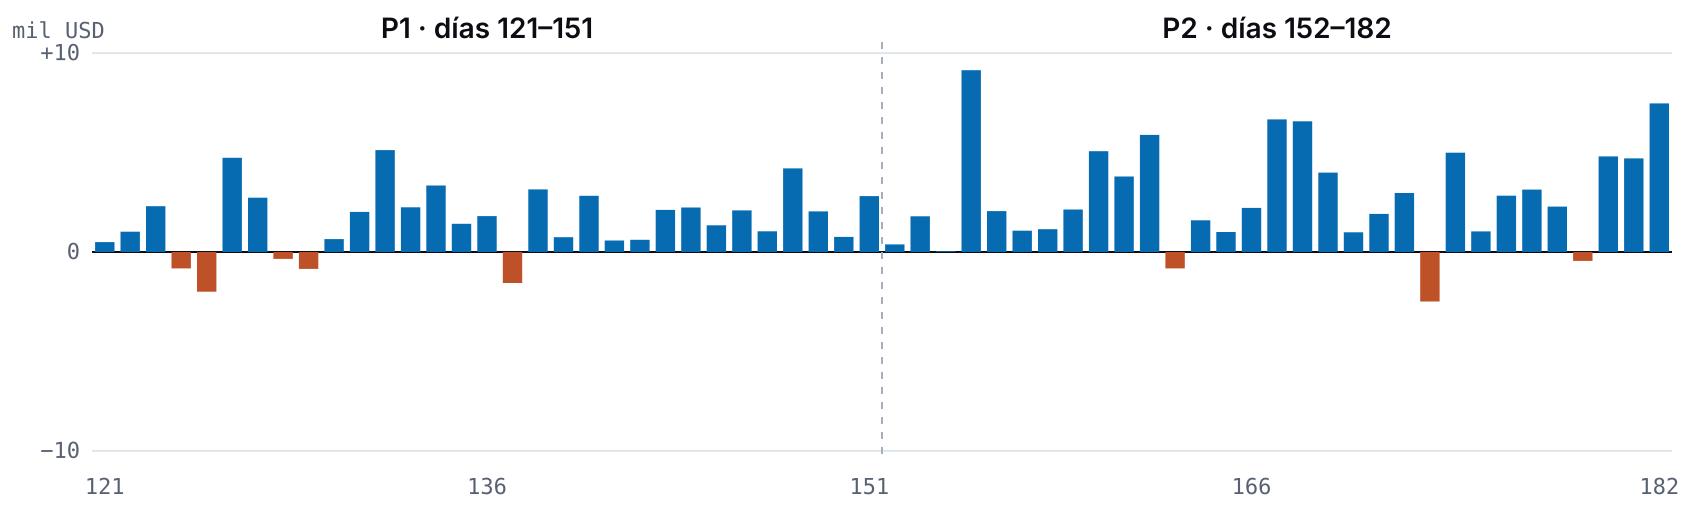

In [27]:
fig("traza"); fig("diario")

## 6. Mantenimiento: búsqueda de variables con validación cruzada temporal

Después de la prueba se buscó si una mejor ingeniería de variables agregaba dinero, con un diseño registrado antes de
correr (`docs/anexo_variables.md`): ocho grupos candidatos, selección hacia adelante en tres ventanas con origen móvil
(un grupo entra si sube el total al menos 1% y mejora en dos de las tres), una rejilla de hiperparámetros con parada
temprana, un bloque de confirmación (días 106–120) que la búsqueda no usa y una sola lectura posterior de la prueba.

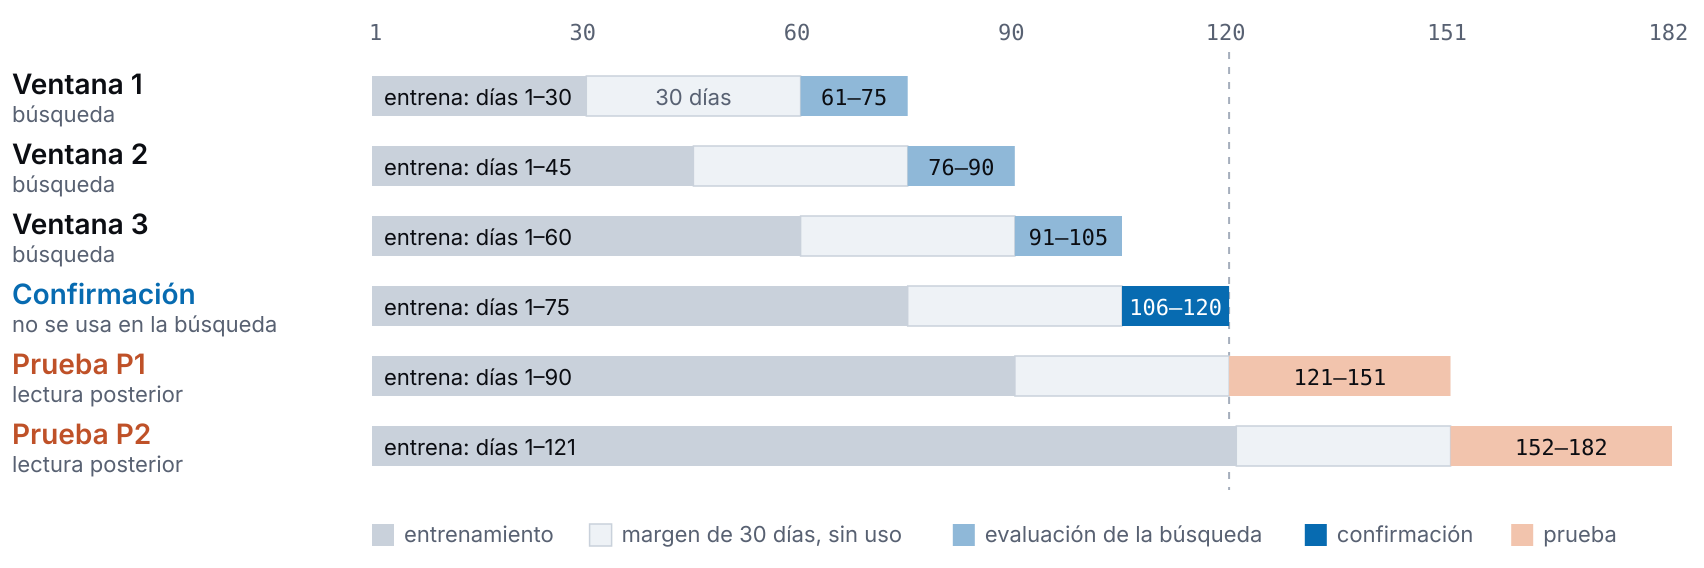

In [28]:
fig("validacion")

In [29]:
rd = pd.DataFrame([{"ronda": r["ronda"], **{g: f"{v['ganancia'] * 100:+.1f}% · {v['suben']} de 3" for g, v in r["pruebas"].items()},
                    "acepta": r["mejor"] if r["acepta"] else "ninguno"} for r in VA["rondas"]]).set_index("ronda").T
print(f"Aceptados: {', '.join(VA['elegidos'])} · validación interna: {VA['base_F3']['total_usd'] / 1e3:,.1f} → "
      f"{VA['final_interno']['total_usd'] / 1e3:,.1f} mil USD ({pc(VA['final_interno']['total_usd'] / VA['base_F3']['total_usd'] - 1)})")
print(f"Rejilla de hiperparámetros: {'se adopta' if VA['hiperparametros']['adopta'] else 'no supera la barra'} "
      f"(mejor combinación {pc(VA['hiperparametros']['ganancia'])}); parada temprana en {VA['aprendizaje']['mejor_iteracion']} árboles")
rd.fillna("—")

Aceptados: perfil, novedad, uid_fino · validación interna: 296.0 → 314.1 mil USD (+6.1%)
Rejilla de hiperparámetros: no supera la barra (mejor combinación -1.5%); parada temprana en 618 árboles


ronda,1,2,3,4
ventanas,+0.4% · 1 de 3,-0.4% · 1 de 3,-1.1% · 1 de 3,-2.0% · 0 de 3
perfil,+2.5% · 2 de 3,—,—,—
novedad,+0.2% · 2 de 3,+1.9% · 2 de 3,—,—
compartido,+1.1% · 2 de 3,+1.2% · 3 de 3,-2.5% · 1 de 3,-6.1% · 0 de 3
texto,+1.1% · 2 de 3,+0.5% · 1 de 3,-1.7% · 1 de 3,-2.4% · 1 de 3
monto_fino,+1.0% · 2 de 3,+0.6% · 2 de 3,+0.2% · 2 de 3,-4.8% · 1 de 3
frecuencia,-4.2% · 1 de 3,-2.9% · 2 de 3,-6.5% · 0 de 3,-6.0% · 0 de 3
uid_fino,-0.4% · 1 de 3,-1.6% · 1 de 3,+1.6% · 3 de 3,—
acepta,perfil,novedad,uid_fino,ninguno


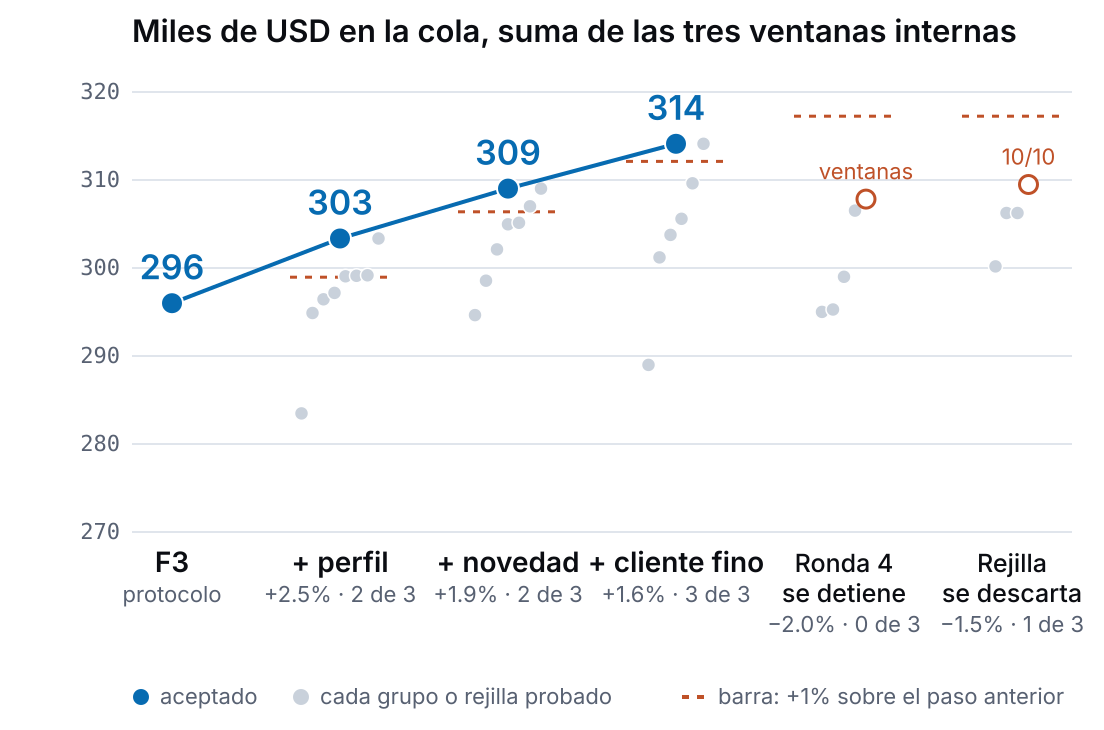

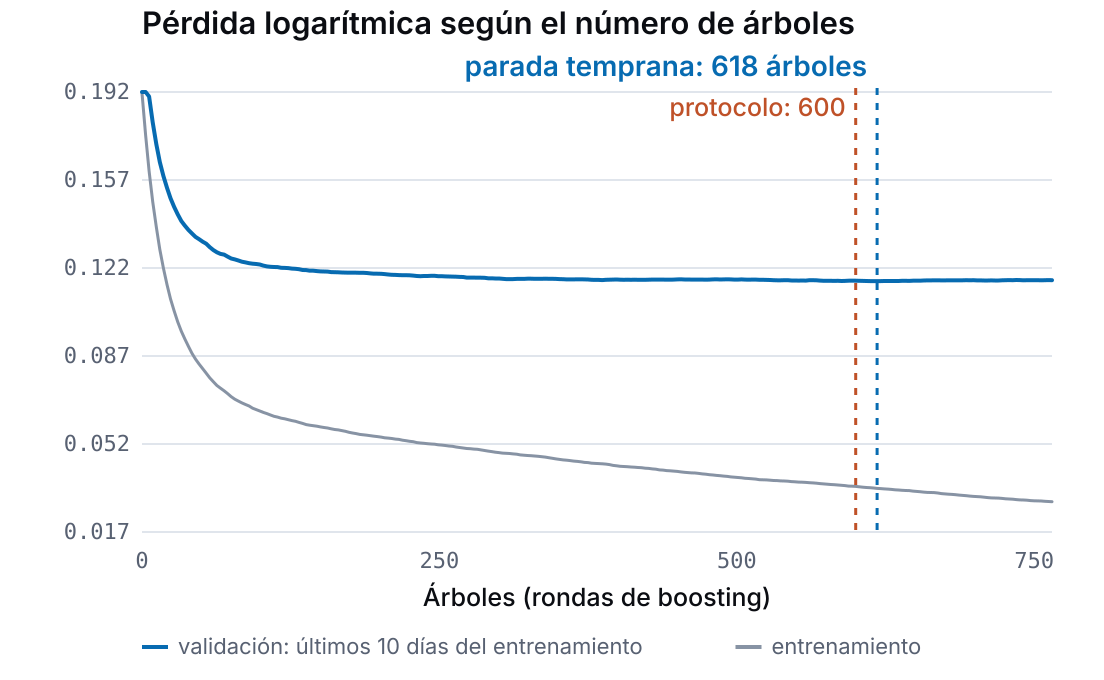

In [30]:
fig("escalada"); fig("aprendizaje")

**Confirmación, recalculada en vivo** desde los puntajes guardados de los días 106–120.

In [31]:
cf = pd.read_parquet(PROCESADOS / "variables_confirmacion.parquet")
dia, y, m = cf["dia"].to_numpy(), cf["fraude"].to_numpy(), cf["monto"].to_numpy()
usd_c = {n: dinero(cf[n].to_numpy() * m, dia, y, m, K) for n in ("F3", "elegido", "con_etiquetas", "logit_F3", "logit_elegido", "regla")}
assert max(abs(usd_c[n] - VA["confirmacion_resultados"]["usd"][n]) for n in usd_c) < 0.01
cc6 = VA["confirmacion_resultados"]["contrastes"]
ETIQ = {"F3": "XGBoost con F3", "elegido": "XGBoost con variables nuevas", "con_etiquetas": "con historial de contracargos (cota)",
        "logit_F3": "logística con F3", "logit_elegido": "logística con variables nuevas", "regla": "mejor regla"}
display(pd.DataFrame({"mil USD, días 106–120": {ETIQ[n]: mil(v) for n, v in usd_c.items()}}))
pd.DataFrame({"contraste": ["variables nuevas contra F3", "logística con variables nuevas contra logística con F3", "historial de contracargos contra variables nuevas"],
              "ventaja": [pc(cc6[k]["rel"]) for k in ("elegido_vs_F3", "logit_elegido_vs_logit_F3", "con_etiquetas_vs_elegido")],
              "IC 95%": [ic(cc6[k]["rel_ic95"]) for k in ("elegido_vs_F3", "logit_elegido_vs_logit_F3", "con_etiquetas_vs_elegido")]}).set_index("contraste")

,"mil USD, días 106–120"
XGBoost con F3,167.3
XGBoost con variables nuevas,158.4
con historial de contracargos (cota),177.9
logística con F3,163.5
logística con variables nuevas,165.1
mejor regla,139.0


,ventaja,IC 95%
contraste,,
variables nuevas contra F3,-5.3%,-9.6% a -1.1%
logística con variables nuevas contra logística con F3,+1.0%,-3.3% a +5.3%
historial de contracargos contra variables nuevas,+12.2%,+7.1% a +17.9%


**Lectura posterior de la prueba**, recalculada en vivo. F3 reconstruido debe reproducir la corrida congelada.

In [32]:
lec = {}
for x in P:
    a = pd.read_parquet(PROCESADOS / f"anexo_puntajes_{x}.parquet")
    dia, y, m = a["dia"].to_numpy(), a["fraude"].to_numpy(), a["monto"].to_numpy()
    lec[x] = {n: dinero(a[n].to_numpy() * m, dia, y, m, K) for n in ("F3", "elegido", "logit_F3", "logit_elegido")}
    assert abs(lec[x]["F3"] - R[x]["usd"][FINAL]) < 0.01, "F3 no reproduce la prueba congelada"
pd.DataFrame({x: {"F3 (mil USD)": mil(lec[x]["F3"]), "variables nuevas (mil USD)": mil(lec[x]["elegido"]),
                  "variables nuevas contra F3": f"{pc(AX[x]['contrastes']['elegido_vs_F3']['rel'])} ({ic(AX[x]['contrastes']['elegido_vs_F3']['rel_ic95'])})",
                  "logística: nuevas contra F3": f"{pc(AX[x]['contrastes']['logit_elegido_vs_logit_F3']['rel'])} ({ic(AX[x]['contrastes']['logit_elegido_vs_logit_F3']['rel_ic95'])})"}
              for x in P})

,P1,P2
F3 (mil USD),211.4,226.7
variables nuevas (mil USD),214.6,226.7
variables nuevas contra F3,+1.5% (-2.4% a +6.2%),+0.0% (-3.1% a +3.8%)
logística: nuevas contra F3,+5.1% (+0.5% a +10.0%),+2.2% (-1.7% a +7.2%)


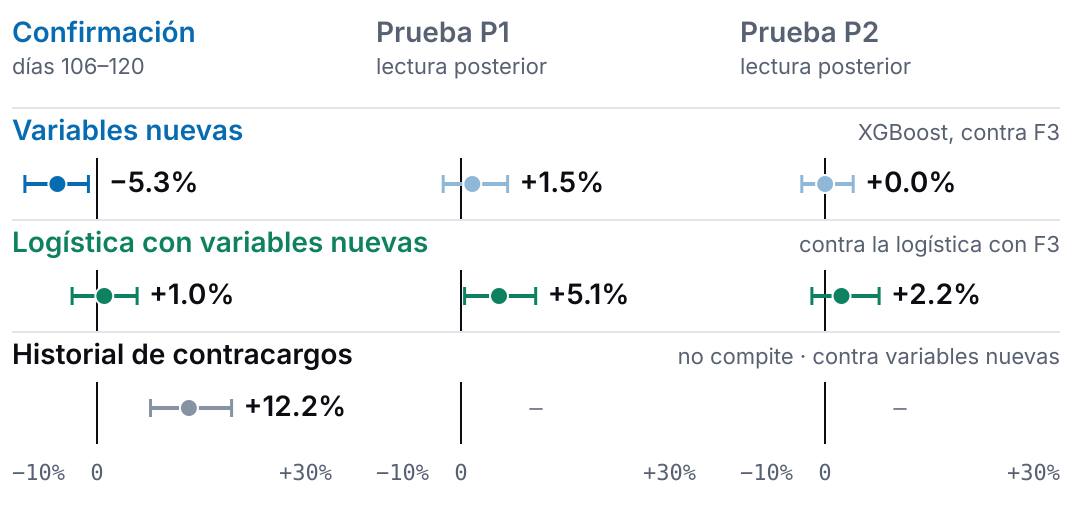

In [33]:
fig("confirmacion")

In [34]:
e = cc6["elegido_vs_F3"]
Markdown(f"""**Lectura.** En validación interna, los grupos aceptados suben el dinero
{pc(VA['final_interno']['total_usd'] / VA['base_F3']['total_usd'] - 1)}, pero esas ventanas son las mismas que los eligieron.
En los días de confirmación, el modelo con variables nuevas lleva {pc(e['rel'])} contra F3 (IC 95%: {ic(e['rel_ic95'])}). La ganancia
no se repite en días nuevos, así que **F3 se mantiene** y el veredicto del protocolo no cambia.""")

**Lectura.** En validación interna, los grupos aceptados suben el dinero
+6.1%, pero esas ventanas son las mismas que los eligieron.
En los días de confirmación, el modelo con variables nuevas lleva -5.3% contra F3 (IC 95%: -9.6% a -1.1%). La ganancia
no se repite en días nuevos, así que **F3 se mantiene** y el veredicto del protocolo no cambia.

## 7. Despliegue

| Etapa | Cuándo | Qué se hace |
|---|---|---|
| Operación | Cada noche | Se puntúan los pagos del día y los 60 con mayor fraude esperado pasan a la cola. La decisión sobre cada pago sigue siendo del equipo. |
| Reentrenamiento | Cada semana | Con los pagos de más de 30 días, que ya tienen etiqueta. |
| Piloto | Primer mes | Los días se asignan al azar a la cola actual o a la del modelo, para medir el efectivo recuperado. |
| Monitoreo | Cada semana | Dólares por revisión, precisión, monto medio de la cola y mezcla de productos. |
| Respaldo | Si el modelo falla | Si durante dos semanas queda por debajo de la regla, se vuelve a la tabla por segmento. |

In [35]:
tot = lambda n: sum(vivo[x][n] for x in P)
Markdown(f"""## 8. Conclusión

Con las mismas 60 revisiones diarias, en los días 121–182 la mejor regla lleva {tot(REGLA) / 1e3:,.0f} mil USD de fraude a la cola,
la logística {tot(LOGIT) / 1e3:,.0f} mil y el modelo {tot(FINAL) / 1e3:,.0f} mil. Contra la regla, la ventaja es de
{pc(R['P1']['contrastes'][REGLA]['rel'])} y {pc(R['P2']['contrastes'][REGLA]['rel'])}; contra la logística, de
{pc(R['P1']['contrastes'][LOGIT]['rel'])} y {pc(R['P2']['contrastes'][LOGIT]['rel'])}. Las tres hipótesis fijadas antes de la prueba
se cumplen en los dos meses.

Quedan dos preguntas que estos datos no responden: cuánto efectivo se recupera realmente y cómo se compara el modelo con la
práctica actual de Vesta. Un piloto con asignación aleatoria de días permite medir ambas.""")

## 8. Conclusión

Con las mismas 60 revisiones diarias, en los días 121–182 la mejor regla lleva 301 mil USD de fraude a la cola,
la logística 372 mil y el modelo 438 mil. Contra la regla, la ventaja es de
+30.1% y +63.4%; contra la logística, de
+13.1% y +22.2%. Las tres hipótesis fijadas antes de la prueba
se cumplen en los dos meses.

Quedan dos preguntas que estos datos no responden: cuánto efectivo se recupera realmente y cómo se compara el modelo con la
práctica actual de Vesta. Un piloto con asignación aleatoria de días permite medir ambas.